# Chapter 13: Project: analysing a year of coffee-shop sales

This chapter is a complete analysis from start to finish. You are the new data analyst at Brew & Byte, and the owners hand you a year of sales data with a list of questions. You will load and clean the data, build useful columns, join the tables, summarise, chart, test one claim statistically and write up what you found.

Nothing here is new. Every step uses a tool from an earlier chapter, and each section says which one. The goal is to see how the pieces fit together in a real workflow, and to practise the habit that matters most: **start from questions, not from code**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

## 13.1 The questions

Before writing any code, write down what you want to know. It keeps the analysis focused and tells you which columns you need. The owners asked:

1. **Where does the money come from?** Which stores, which items and which hours bring in the most revenue?
2. **When are we busiest?** How much bigger are weekends? Is December really a strong month?
3. **Does rain hurt sales?** Staff say rainy days are quiet. Is that real or just a feeling? (We will test it.)
4. **Does heat sell Cold Brew?** Should we stock more on hot days?
5. **Are loyalty customers worth it?** Do card holders spend more per order than walk-ins?
6. **Do customer tiers mean anything?** Do Gold customers actually spend more than Bronze?

For each question, note what you will need: question 3 needs daily revenue joined with rainfall, question 6 needs orders joined with customers, and so on.

## 13.2 Load and check the data

First look before you touch anything (Chapter 6): shape, types, missing values. `parse_dates` turns the timestamp text into real datetimes (Chapter 9).

In [2]:
orders = pd.read_csv("data/orders.csv", parse_dates=["timestamp"])
customers = pd.read_csv("data/customers.csv", parse_dates=["joined"])
stores = pd.read_csv("data/stores.csv")
weather = pd.read_csv("data/weather.csv", parse_dates=["date"])

for name, df in [("orders", orders), ("customers", customers), ("stores", stores), ("weather", weather)]:
    print(f"{name:10s} {df.shape}")
orders.head(3)

orders     (53203, 9)
customers  (600, 6)
stores     (4, 4)
weather    (1098, 4)


,order_id,timestamp,store_id,customer_id,item,category,qty,unit_price,payment
0,100001,2024-01-01 17:24:00,S1,C0417,Croissant,Bakery,1,140,UPI
1,100002,2024-01-01 12:28:00,S1,NaN,Masala Chai,Tea,2,90,UPI
2,100003,2024-01-01 16:56:00,S1,NaN,Sandwich,Food,1,220,UPI


In [3]:
print(orders.dtypes)
print()
print(orders.isna().sum())

order_id                int64
timestamp      datetime64[us]
store_id                  str
customer_id               str
item                      str
category                  str
qty                     int64
unit_price              int64
payment                   str
dtype: object

order_id           0
timestamp          0
store_id           0
customer_id    24140
item               0
category           0
qty                0
unit_price         0
payment            0
dtype: int64


Text columns load as `str` (pandas 3) and the timestamp is a datetime. The only missing values are in `customer_id`. That is not an error: an empty customer means a **walk-in** who did not show a loyalty card. We keep these rows and will use the gap as information.

A few quick sanity checks catch problems early. An `assert` stops the notebook if a check fails.

In [4]:
assert orders["timestamp"].dt.year.eq(2024).all()
assert (orders["qty"] > 0).all() and (orders["unit_price"] > 0).all()
print("stores in orders:", sorted(orders["store_id"].unique()))
print("orders:", orders["order_id"].nunique(), " order lines:", len(orders))

stores in orders: ['S1', 'S2', 'S3', 'S4']
orders: 35489  order lines: 53203


One order can contain several lines (a latte and a croissant are two rows with the same `order_id`). Keep this in mind: counting rows counts **items**, not **orders**.

## 13.3 Clean the customer table

The customers file has two known issues (see Chapter 7): some ages are missing, and the tier is not always spelled the same way.

In [5]:
print(customers["tier"].value_counts())
print("missing ages:", customers["age"].isna().sum())

tier
Bronze    365
Silver    157
Gold       58
silver      8
bronze      7
gold        5
Name: count, dtype: int64
missing ages: 25


"gold" and "Gold" would be counted as different tiers. Standardising the text fixes it. We leave missing ages as they are, since we do not need age for our questions, and guessing a value would only add noise.

In [6]:
customers["tier"] = customers["tier"].str.strip().str.title()
print(customers["tier"].value_counts())
assert set(customers["tier"]) == {"Bronze", "Silver", "Gold"}

tier
Bronze    372
Silver    165
Gold       63
Name: count, dtype: int64


Three clean tiers. Note that we reassigned the column instead of using `inplace=True`, as pandas 3 expects.

## 13.4 Build features

Most questions need columns that are not in the raw file. We add them once, here, so every later section can use them (Chapters 5 and 9).

In [7]:
orders["line_total"] = orders["qty"] * orders["unit_price"]
orders["date"] = orders["timestamp"].dt.normalize()
orders["hour"] = orders["timestamp"].dt.hour
orders["weekday"] = orders["timestamp"].dt.day_name()
orders["month"] = orders["timestamp"].dt.month
orders["is_member"] = orders["customer_id"].notna()

orders[["timestamp", "date", "hour", "weekday", "month", "is_member", "line_total"]].head(3)

,timestamp,date,hour,weekday,month,is_member,line_total
0,2024-01-01 17:24:00,2024-01-01,17,Monday,1,True,140
1,2024-01-01 12:28:00,2024-01-01,12,Monday,1,False,180
2,2024-01-01 16:56:00,2024-01-01,16,Monday,1,False,220


`day_name()` gives text, which would sort alphabetically (Friday first). We keep a list of the days in the right order to use when sorting and plotting.

In [8]:
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(f"total revenue for 2024: {orders['line_total'].sum():,} rupees")

total revenue for 2024: 9,599,840 rupees


## 13.5 Join the tables

Questions about cities, weather and tiers need the other tables. Two joins do most of the work (Chapter 8).

**Store-day table.** Weather is recorded per city per day, so we first summarise orders to one row per store per day, then attach the city and the weather. A helper column with Cold Brew cups (0 for every other item) lets one `groupby` count them too.

In [9]:
orders["cold_brew_qty"] = orders["qty"].where(orders["item"] == "Cold Brew", 0)

daily = (orders.groupby(["store_id", "date"])
         .agg(revenue=("line_total", "sum"),
              n_orders=("order_id", "nunique"),
              cold_brew=("cold_brew_qty", "sum"))
         .reset_index())
daily = daily.merge(stores[["store_id", "city", "seats"]], on="store_id", how="left")
daily = daily.merge(weather, on=["date", "city"], how="left", validate="many_to_one")

assert daily["temp_c"].notna().all()       # every store-day found its weather
print(daily.shape)
daily.head(3)

(1464, 9)


,store_id,date,revenue,n_orders,cold_brew,city,seats,temp_c,rain_mm
0,S1,2024-01-01,6650,22,4,Pune,40,23.4,0.0
1,S1,2024-01-02,6040,18,3,Pune,40,19.7,0.0
2,S1,2024-01-03,5940,25,3,Pune,40,23.7,0.0


`validate="many_to_one"` makes pandas check that each store-day matches at most one weather row; if the weather file had duplicates, the merge would fail loudly instead of silently multiplying rows. The `assert` checks the other direction: no store-day was left without weather.

**Orders with customers.** A left join keeps every order line, including walk-ins, whose customer columns simply stay empty.

In [10]:
orders_c = orders.merge(customers[["customer_id", "tier", "home_store"]],
                        on="customer_id", how="left", validate="many_to_one")
assert len(orders_c) == len(orders)        # a left join must not add rows
print(orders_c["tier"].value_counts(dropna=False))

tier
NaN       24140
Bronze    17897
Silver     8113
Gold       3053
Name: count, dtype: int64


## 13.6 Where does the money come from?

### By store

Total revenue tells you which store is biggest. Revenue per seat is fairer when stores have different sizes.

In [11]:
by_store = (daily.groupby(["store_id", "city", "seats"])["revenue"].sum()
            .reset_index()
            .assign(share=lambda d: d["revenue"] / d["revenue"].sum(),
                    per_seat=lambda d: d["revenue"] / d["seats"])
            .round({"share": 3, "per_seat": 0}))
by_store

,store_id,city,seats,revenue,share,per_seat
0,S1,Pune,40,2520200,0.263,63005.0
1,S2,Pune,24,1548340,0.161,64514.0
2,S3,Mumbai,55,3492800,0.364,63505.0
3,S4,Bengaluru,32,2038500,0.212,63703.0


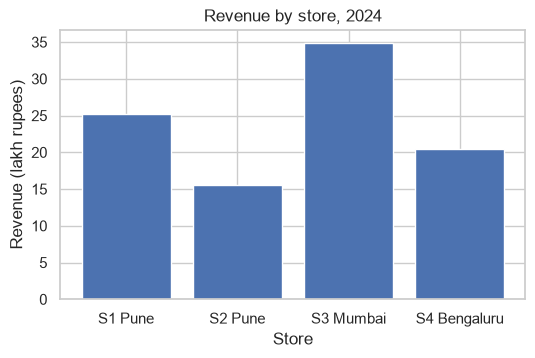

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_store["store_id"] + " " + by_store["city"], by_store["revenue"] / 1e5)
ax.set_xlabel("Store")
ax.set_ylabel("Revenue (lakh rupees)")
ax.set_title("Revenue by store, 2024")
plt.show()

S3 in Mumbai is the biggest store and earns the most, and S2 the least. Per seat, though, the four stores are close: revenue tracks the number of seats almost exactly. Bigger stores earn more because they serve more people, not because each seat works harder.

### By item

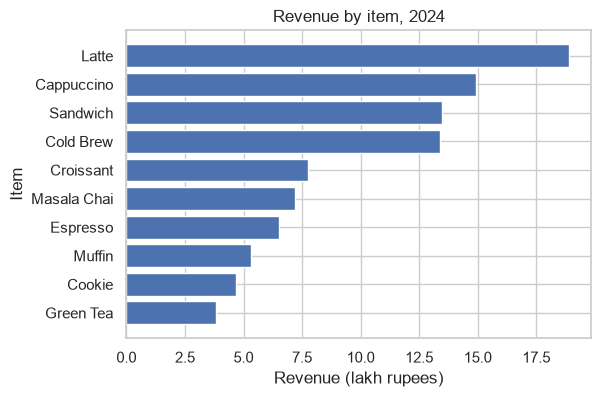

category
Coffee    0.560
Bakery    0.185
Food      0.140
Tea       0.115
Name: line_total, dtype: float64


In [13]:
by_item = orders.groupby("item")["line_total"].sum().sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(by_item.index, by_item / 1e5)
ax.set_xlabel("Revenue (lakh rupees)")
ax.set_ylabel("Item")
ax.set_title("Revenue by item, 2024")
plt.show()

by_category = orders.groupby("category")["line_total"].sum()
print((by_category / by_category.sum()).sort_values(ascending=False).round(3))

Latte is the top earner, ahead of Cappuccino, Sandwich and Cold Brew. The cheap items (Cookie, Green Tea) bring in the least. By category, coffee drinks bring in more than half of all revenue.

### By hour and weekday

A heatmap shows two dimensions at once (Chapter 11). Each cell is the **average** revenue in that hour on that weekday, so days that occur 52 or 53 times are comparable.

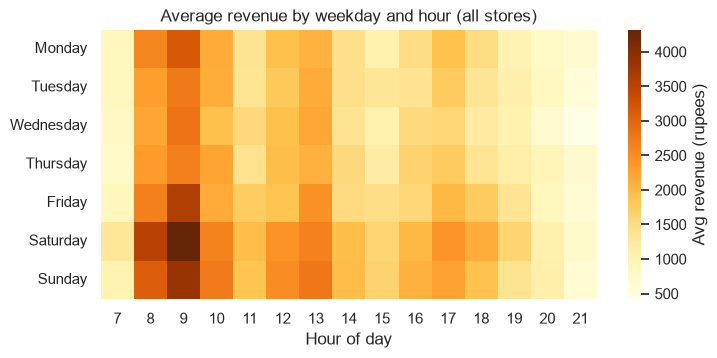

In [14]:
n_days = orders.groupby("weekday")["date"].nunique()
grid = (orders.pivot_table(index="weekday", columns="hour", values="line_total", aggfunc="sum")
        .div(n_days, axis=0)
        .reindex(DAYS))

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(grid, cmap="YlOrBr", ax=ax, cbar_kws={"label": "Avg revenue (rupees)"})
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
ax.set_title("Average revenue by weekday and hour (all stores)")
plt.show()

The darkest band is the morning rush around 8:00–10:00, with a second, smaller peak at lunch (12:00–13:00) and a small bump in the early evening. Saturday and Sunday rows are darker across the whole day. Late evening is quiet everywhere.

## 13.7 Weekends and December

Now we measure the "when" effects with numbers. We first total revenue across stores per day, then average by weekday and by month.

In [15]:
chain = daily.groupby("date")["revenue"].sum()
by_weekday = chain.groupby(chain.index.day_name()).mean().reindex(DAYS)

weekend_avg = by_weekday[["Saturday", "Sunday"]].mean()
weekday_avg = by_weekday[DAYS[:5]].mean()
weekend_lift = weekend_avg / weekday_avg - 1
print(by_weekday.round(0))
print(f"weekend days earn {weekend_lift:.0%} more than weekdays on average")

date
Monday       24109.0
Tuesday      23216.0
Wednesday    22474.0
Thursday     23842.0
Friday       26725.0
Saturday     32466.0
Sunday       30870.0
Name: revenue, dtype: float64
weekend days earn 32% more than weekdays on average


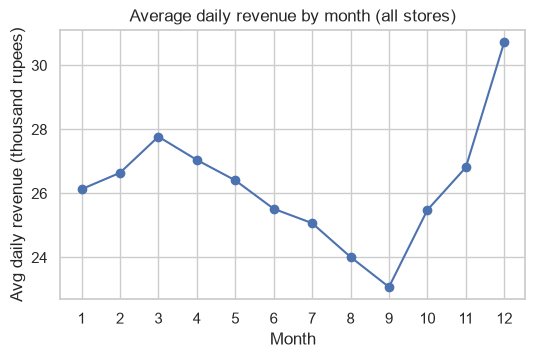

December vs the average of other months: +19%


In [16]:
by_month = chain.groupby(chain.index.month).mean()
dec_lift = by_month[12] / by_month.drop(12).mean() - 1

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(by_month.index, by_month / 1000, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Avg daily revenue (thousand rupees)")
ax.set_title("Average daily revenue by month (all stores)")
plt.show()
print(f"December vs the average of other months: {dec_lift:+.0%}")

December is the best month by a clear margin. There is also a dip from June to September. That is the monsoon, which hints at the next question.

## 13.8 Weather: does rain hurt sales?

This is a claim we can **test** (Chapter 12). We call a day "rainy" when more than 10 mm of rain fell in that store's city. A box plot shows the two groups for each store (Chapter 11).

rainy
False    1225
True      239
Name: count, dtype: int64


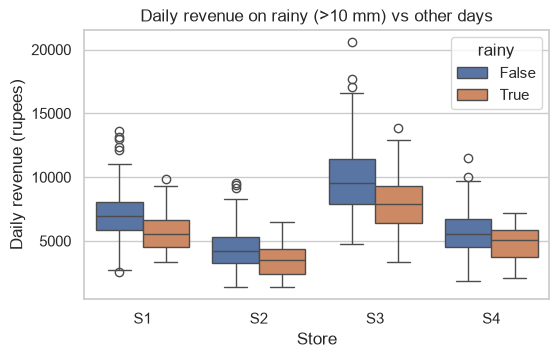

In [17]:
daily["rainy"] = daily["rain_mm"] > 10
print(daily["rainy"].value_counts())

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(data=daily, x="store_id", y="revenue", hue="rainy", ax=ax)
ax.set_xlabel("Store")
ax.set_ylabel("Daily revenue (rupees)")
ax.set_title("Daily revenue on rainy (>10 mm) vs other days")
plt.show()

The rainy boxes sit lower in every store. To check this is not just luck, we run a Welch t-test (see 12.4) **separately for each store**. Testing per store matters: S3 is much bigger than S2, so pooling all stores would mix store size with the rain effect.

In [18]:
rows = []
for store, g in daily.groupby("store_id"):
    wet, dry = g.loc[g["rainy"], "revenue"], g.loc[~g["rainy"], "revenue"]
    res = stats.ttest_ind(wet, dry, equal_var=False)
    rows.append({"store": store, "rainy_days": len(wet), "dry_mean": dry.mean(),
                 "rainy_mean": wet.mean(), "change": wet.mean() / dry.mean() - 1,
                 "p_value": res.pvalue})
rain_test = pd.DataFrame(rows)
rain_test.round({"dry_mean": 0, "rainy_mean": 0, "change": 3})

,store,rainy_days,dry_mean,rainy_mean,change,p_value
0,S1,61,7108.0,5776.0,-0.187,4.451026e-08
1,S2,61,4359.0,3588.0,-0.177,4.414432e-05
2,S3,64,9860.0,8048.0,-0.184,4.377722e-08
3,S4,53,5701.0,4796.0,-0.159,1.727221e-05


In every store, rainy days bring in noticeably less, and every p-value is far below 0.05. 

There is a trap here, though. Almost all rainy days fall in the monsoon, and the monsoon months might be slow for other reasons (holidays, for example). If so, we would be blaming rain for a seasonal dip. A fairer test compares rainy and dry days **within** the monsoon months only.

In [19]:
monsoon = daily[daily["date"].dt.month.between(6, 9)]
wet, dry = monsoon.loc[monsoon["rainy"], "revenue"], monsoon.loc[~monsoon["rainy"], "revenue"]
res = stats.ttest_ind(wet, dry, equal_var=False)
print(f"monsoon only: rainy mean {wet.mean():.0f}, dry mean {dry.mean():.0f}, p = {res.pvalue:.1e}")

monsoon only: rainy mean 5606, dry mean 6562, p = 4.8e-05


Even inside the monsoon, heavy-rain days earn less and the difference is still very unlikely to be luck. So the staff were right: rain itself cuts sales, not just the season. (This check still pools stores; exercise 1 asks you to make it fairer.)

## 13.9 Weather: does heat sell Cold Brew?

Instead of a raw count, we use Cold Brew cups **per order**, so busy days do not look like "Cold Brew days" just because they are busy. Grouping temperature into bands with `pd.cut` (Chapter 7) makes the pattern easy to read.

In [20]:
daily["cb_per_order"] = daily["cold_brew"] / daily["n_orders"]
daily["temp_band"] = pd.cut(daily["temp_c"], bins=[15, 23, 26, 29, 32, 36],
                            labels=["<23", "23-26", "26-29", "29-32", "32+"])
by_band = daily.groupby("temp_band", observed=True)["cb_per_order"].agg(["mean", "size"])
print(by_band.round(3))

            mean  size
temp_band             
<23        0.145   317
23-26      0.138   401
26-29      0.143   436
29-32      0.343   259
32+        0.338    51


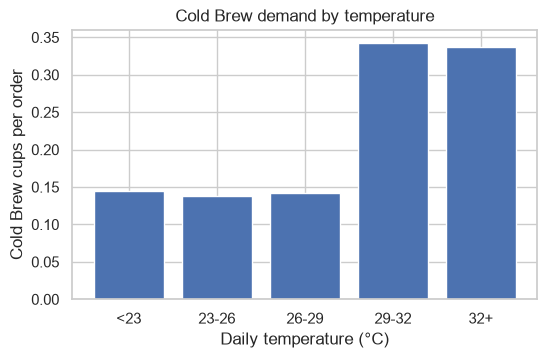

Spearman rho = 0.41, p = 8.5e-60


In [21]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_band.index.astype(str), by_band["mean"])
ax.set_xlabel("Daily temperature (°C)")
ax.set_ylabel("Cold Brew cups per order")
ax.set_title("Cold Brew demand by temperature")
plt.show()

rho, p = stats.spearmanr(daily["temp_c"], daily["cb_per_order"])
print(f"Spearman rho = {rho:.2f}, p = {p:.1e}")

Cold Brew per order is flat up to about 29 °C and then jumps sharply: above that it more than doubles. The rank correlation (see 12.6) is positive with a tiny p-value. Practical meaning: stock up on Cold Brew when the forecast is above about 29 °C, which mostly matters in Mumbai and Pune; Bengaluru rarely gets that hot.

In [22]:
print((daily["temp_c"] > 29).groupby(daily["city"]).mean().round(2))

city
Bengaluru    0.07
Mumbai       0.37
Pune         0.20
Name: temp_c, dtype: float64


## 13.10 Customers: members, walk-ins and tiers

### Members vs walk-ins

We compare **orders**, not order lines. So first we total each order, then compare the two groups.

In [23]:
per_order = orders.groupby("order_id").agg(value=("line_total", "sum"),
                                           items=("qty", "sum"),
                                           member=("is_member", "first"))
members = per_order.groupby("member").agg(orders=("value", "size"),
                                          avg_value=("value", "mean"),
                                          avg_items=("items", "mean"))
members["share_of_orders"] = members["orders"] / members["orders"].sum()
members.round(2)

,orders,avg_value,avg_items,share_of_orders
member,,,,
False,16050,271.75,1.88,0.45
True,19439,269.47,1.87,0.55


Loyalty-card holders place a little over half of all orders, but their average order value is almost the same as a walk-in's. The card brings people in; it does not make them spend more per visit.

### Tiers

Do Gold customers spend more over the year? We total revenue per customer and attach the tier. Starting from the customer table with a left join keeps customers who never ordered (they would count as 0).

In [24]:
per_customer = (orders.dropna(subset=["customer_id"])
                .groupby("customer_id")
                .agg(revenue=("line_total", "sum"), n_orders=("order_id", "nunique")))
cust = customers.merge(per_customer, on="customer_id", how="left").fillna({"revenue": 0, "n_orders": 0})
by_tier = cust.groupby("tier")[["revenue", "n_orders"]].mean().reindex(["Bronze", "Silver", "Gold"])
by_tier["customers"] = cust["tier"].value_counts()
by_tier.round(1)

,revenue,n_orders,customers
tier,,,
Bronze,8679.1,32.2,372
Silver,8812.7,33.0,165
Gold,8819.2,32.0,63


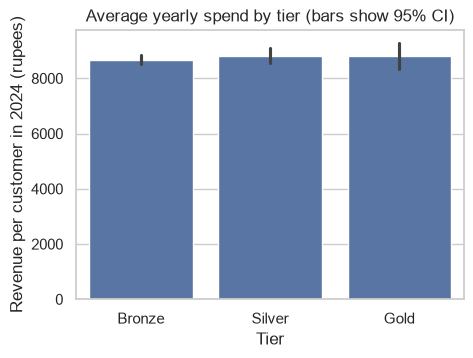

In [25]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(data=cust, x="tier", y="revenue", order=["Bronze", "Silver", "Gold"], ax=ax)
ax.set_xlabel("Tier")
ax.set_ylabel("Revenue per customer in 2024 (rupees)")
ax.set_title("Average yearly spend by tier (bars show 95% CI)")
plt.show()

The three bars are about the same height and their confidence intervals overlap heavily. In this data the tier label does **not** go with higher spending. That is a finding worth reporting: either the tiers are assigned on something other than spending, or the scheme needs a rethink.

## 13.11 Findings and next steps

A good analysis ends with a short summary that a busy reader can act on. We build it from the variables computed above, so the numbers can never drift away from the analysis.

In [26]:
top = by_store.sort_values("revenue", ascending=False).iloc[0]
findings = pd.DataFrame([
    ("Biggest store", f"{top['store_id']} ({top['city']}), {top['share']:.0%} of revenue; revenue per seat is similar everywhere"),
    ("Top item", f"{by_item.index[-1]}, followed by {by_item.index[-2]}"),
    ("Peak hours", "morning rush 8:00-10:00, smaller lunch peak 12:00-13:00"),
    ("Weekend effect", f"weekend days earn about {weekend_lift:.0%} more than weekdays"),
    ("December effect", f"about {dec_lift:.0%} above the average of other months"),
    ("Rain (>10 mm)", f"daily revenue {rain_test['change'].min():.0%} to {rain_test['change'].max():.0%} per store; significant, also within the monsoon"),
    ("Heat and Cold Brew", f"Cold Brew per order jumps above ~29 °C (Spearman rho = {rho:.2f})"),
    ("Members vs walk-ins", f"members place {members.loc[True, 'share_of_orders']:.0%} of orders; same order value as walk-ins"),
    ("Tiers", "no clear spending difference between Bronze, Silver and Gold"),
], columns=["Question", "Finding"])
print(findings.to_string(index=False))

           Question                                                                    Finding
      Biggest store        S3 (Mumbai), 36% of revenue; revenue per seat is similar everywhere
           Top item                                              Latte, followed by Cappuccino
         Peak hours                    morning rush 8:00-10:00, smaller lunch peak 12:00-13:00
     Weekend effect                             weekend days earn about 32% more than weekdays
    December effect                                about 19% above the average of other months
      Rain (>10 mm) daily revenue -19% to -16% per store; significant, also within the monsoon
 Heat and Cold Brew               Cold Brew per order jumps above ~29 °C (Spearman rho = 0.41)
Members vs walk-ins                  members place 55% of orders; same order value as walk-ins
              Tiers               no clear spending difference between Bronze, Silver and Gold


### Next steps: forecasting daily revenue

The owners' next request will be: "how much will each store sell tomorrow?" You now know what drives daily revenue: the store, the day of the week, the month, heavy rain and (for Cold Brew) temperature. These are exactly the **features** a forecasting model needs.

In the **Machine learning** stage you will turn the `daily` table into a training set (one row per store-day, revenue as the target), split it by date so the model is tested on days it has not seen, and fit models from simple linear regression up to gradient boosting. The analysis in this chapter is the baseline those models have to beat.

## 13.12 Lessons learned

| Mistake | What happens | Fix |
|---|---|---|
| Counting rows as orders | Rows are order **lines**, so order counts are inflated | Use `order_id` with `nunique`, or total per order first |
| Comparing totals across stores of different size | The biggest store always "wins" | Also look at a fair rate: per seat, per day, per order |
| Merging without checks | Duplicate keys silently multiply rows | Use `validate=` and `assert len(...)` after the merge |
| Ignoring a confounder (season) when testing rain | You may blame rain for a seasonal dip | Compare like with like, for example within the monsoon only |
| Averaging weekdays by summing | Days that occur 53 times look bigger | Divide by the number of such days, or average daily totals |
| Reporting only p-values | Readers cannot tell if the effect matters | Report the size of the effect (rupees, %) next to the p-value |

## 13.13 Extension exercises

**1.** The monsoon rain test in 13.8 pooled all stores. Make it fairer: for each store, compute rainy and dry mean revenue **within June–September only**, and run a Welch t-test per store. Is the rain effect still there in every store?

In [27]:
# Solution
rows = []
for store, g in daily[daily["date"].dt.month.between(6, 9)].groupby("store_id"):
    wet, dry = g.loc[g["rainy"], "revenue"], g.loc[~g["rainy"], "revenue"]
    rows.append({"store": store, "rainy_days": len(wet), "dry_days": len(dry),
                 "change": wet.mean() / dry.mean() - 1,
                 "p_value": stats.ttest_ind(wet, dry, equal_var=False).pvalue})
pd.DataFrame(rows).round({"change": 3, "p_value": 4})

,store,rainy_days,dry_days,change,p_value
0,S1,59,63,-0.172,0.0001
1,S2,59,63,-0.138,0.0214
2,S3,62,60,-0.180,0.0001
3,S4,53,69,-0.134,0.0050


The effect has the same direction in every store. With fewer days per test the p-values are larger than before, which is exactly what you should expect when you cut the sample.

**2.** Which item has the biggest weekend boost? For each item, compute average units sold per weekend day and per weekday, and the ratio between them. Show the result as a sorted horizontal bar chart.

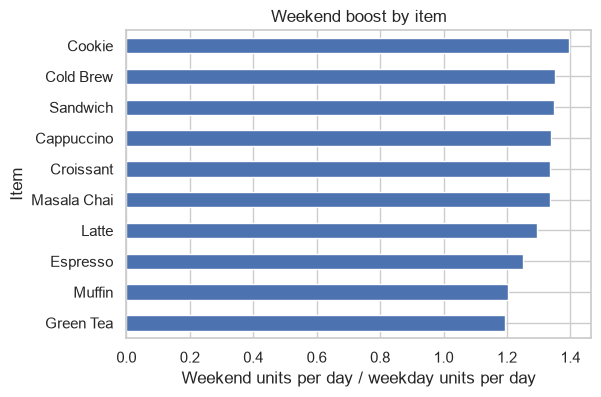

item
Green Tea      1.20
Muffin         1.20
Espresso       1.25
Latte          1.30
Croissant      1.34
Masala Chai    1.34
Cappuccino     1.34
Cold Brew      1.35
Sandwich       1.35
Cookie         1.40
dtype: float64


In [28]:
# Solution
orders["is_weekend"] = orders["timestamp"].dt.day_of_week >= 5
units = orders.groupby(["item", "is_weekend"])["qty"].sum().unstack()
days_per_group = orders.groupby("is_weekend")["date"].nunique()
ratio = (units / days_per_group)[True] / (units / days_per_group)[False]

fig, ax = plt.subplots(figsize=(6, 4))
ratio.sort_values().plot.barh(ax=ax)
ax.set_xlabel("Weekend units per day / weekday units per day")
ax.set_ylabel("Item")
ax.set_title("Weekend boost by item")
plt.show()
print(ratio.round(2).sort_values())

Every item sells more at weekends, and the boosts are of similar size (roughly 1.2 to 1.4 times). Busier weekends come mainly from more customers, not from a very different menu mix.

**3.** Do loyalty members prefer different payment methods from walk-ins? Build a contingency table of `is_member` vs `payment` at the **order** level and run a chi-square test (see 12.5).

In [29]:
# Solution
pay = orders.groupby("order_id").agg(member=("is_member", "first"), payment=("payment", "first"))
table = pd.crosstab(pay["member"], pay["payment"])
res = stats.chi2_contingency(table)
print(table)
print(f"p-value = {res.pvalue:.3f}")
print((table / res.expected_freq).round(3))

payment  Card  Cash    UPI
member                    
False    3886  2472   9692
True     4810  2960  11669
p-value = 0.502
payment   Card   Cash    UPI
member                      
False    0.988  1.006  1.003
True     1.010  0.995  0.997


Look at the observed/expected ratios as well as the p-value: values close to 1.0 mean members and walk-ins pay in much the same way.